# 05 · Avaliação

**CRISP-DM fase 5 — avaliação** · Meridiano Imobiliária

---

Esta fase avalia o projeto como um todo e o modelo selecionado sob a ótica do negócio.

| Etapa | Entrega |
|---|---|
| **5.1 Avaliar os resultados** | modelo validado contra os critérios de sucesso (meta 1.1) · impacto financeiro e operacional estimado · decisão formal sobre a implantação |
| **5.2 Revisar o processo** | análise das fases concluídas · lacunas e erros documentados · sumário das descobertas e limitações |
| **5.3 Determinar as próximas etapas** | próxima ação (Implantação, Iterar mais ou Novo projeto) · justificativa formalizada |

Entradas:
* os segmentos e o resumo do modelo vencedor, salvos pelo [`04-0-modelagem`](04-0-modelagem.ipynb);
* a base pré-processada do [`03-preparacao`](03-preparacao.ipynb);
* a base curada, que dá as unidades de negócio.

In [15]:
import json
import warnings
warnings.filterwarnings('ignore')  # silencia avisos de convergência

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from scipy.stats import kruskal                        # teste: os preços diferem entre segmentos?
from sklearn.ensemble import RandomForestClassifier    # classifica imóveis novos nos segmentos
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

## Critérios e premissas

**Confira estes valores com a meta 1.1 do notebook de entendimento do negócio.** Eles definem se o modelo é aprovado.

* **Críticos:** traduzem o uso do modelo pela Meridiano. Se algum falhar, o modelo não vai para implantação.
* **Não críticos:** qualidade técnica. Se falharem, o modelo pode seguir, mas com ressalva.

As premissas financeiras são **hipotéticas** e precisam ser validadas com a área comercial antes de qualquer decisão.

In [16]:
# Critérios de sucesso do negócio (meta 1.1)
K_MIN, K_MAX = 2, 5           # crítico · número de segmentos que a equipe consegue operar como linha de produto
FATIA_MINIMA = 0.10           # crítico · menor segmento com ao menos 10% da carteira (abaixo disso não paga uma ação dedicada)
RAZAO_PRECO_MINIMA = 1.30     # crítico · preço mediano do segmento mais caro ≥ 1,3× o do mais barato
ACURACIA_MINIMA = 0.85        # crítico · imóvel novo cai no segmento certo em ao menos 85% dos casos
SILHUETA_MINIMA = 0.25        # não crítico · separação geométrica dos grupos

# Premissas financeiras (hipotéticas: validar com a Meridiano)
COMISSAO = 0.06                                                    # comissão média sobre o valor de venda
GANHO_RECEITA = {'pessimista': 0.01, 'base': 0.03, 'otimista': 0.05}  # aumento de receita atribuído à segmentação
CUSTO_IMPLANTACAO = 150_000                                        # US$, uma vez: integração, treinamento da equipe
CUSTO_ANUAL = 40_000                                               # US$ por ano: manutenção e re-treino do modelo

In [17]:
base = pd.read_csv('../data/processed/ames_housing_preprocessed.csv', sep=';')  # saída do 03
base = base.drop(columns=['preco_venda', 'subclasse'], errors='ignore')            # o mesmo espaço usado no 04-0
X = base.to_numpy(dtype=float)

df = pd.read_csv('../data/processed/ames_housing_tratado.csv', sep=';')            # base curada, em unidades de negócio
segmentos = pd.read_csv('../data/processed/segmentos.csv', sep=';')['segmento'].to_numpy()  # rótulos do vencedor (04-0)
selecionado = json.loads(Path('../models/selecionado.json').read_text(encoding='utf-8'))          # nome, parâmetros e silhueta do vencedor

assert len(X) == len(df) == len(segmentos)  # as três bases precisam estar alinhadas linha a linha
validos = segmentos >= 0                     # −1 é ruído (só no dbscan): imóvel sem segmento

display(Markdown(
    f"Modelo selecionado: **{selecionado['modelo']}** · `{selecionado['params']}` · "
    f"**{selecionado['grupos']}** segmentos · silhueta **{selecionado['silhueta']:.3f}**"
))

Modelo selecionado: **mini batch k-means** · `{'batch_size': 256, 'n_clusters': 4}` · **4** segmentos · silhueta **0.105**

# 5.1 · Avaliar os resultados (negócio)

## Os segmentos em unidades de negócio

Os segmentos são renomeados de A em diante, **do mais caro para o mais barato**. A numeração do algoritmo é arbitrária e não deve chegar à equipe comercial.

In [18]:
ordem = (pd.Series(df.loc[validos, 'preco_venda'].to_numpy(), index=segmentos[validos])
         .groupby(level=0).median().sort_values(ascending=False).index)           # segmentos do mais caro ao mais barato
nome = {s: f'Segmento {chr(65 + i)}' for i, s in enumerate(ordem)}                 # 0, 1, 2… → Segmento A, B, C…
df['segmento'] = pd.Series(segmentos).map(nome).fillna('Sem segmento')             # ruído vira "Sem segmento"

colunas_perfil = {  # coluna da base curada: como resumir
    'preco_venda': 'median', 'area_habitavel': 'median', 'qualidade_geral': 'median', 'idade_imovel': 'median',
}
perfil = (
    df.groupby('segmento')
    .agg(imoveis=('preco_venda', 'size'), vgv=('preco_venda', 'sum'),               # vgv: soma do valor de venda
         **{c: (c, f) for c, f in colunas_perfil.items() if c in df})
    .assign(participacao=lambda d: d['imoveis'] / len(df))                          # fatia da carteira
    .sort_values('preco_venda', ascending=False)
)
perfil.style.format({'vgv': '${:,.0f}', 'preco_venda': '${:,.0f}', 'area_habitavel': '{:,.0f}',
                     'participacao': '{:.1%}'})

,imoveis,vgv,preco_venda,area_habitavel,qualidade_geral,idade_imovel,participacao
segmento,,,,,,,
Segmento A,1092,"$267,502,198","$222,500","1,668",7.000000,5.000000,37.3%
Segmento B,1078,"$163,823,710","$144,000","1,208",5.000000,44.000000,36.8%
Segmento C,187,"$25,418,436","$136,000","1,320",6.000000,33.000000,6.4%
Segmento D,570,"$72,459,512","$123,500","1,348",5.000000,83.000000,19.5%


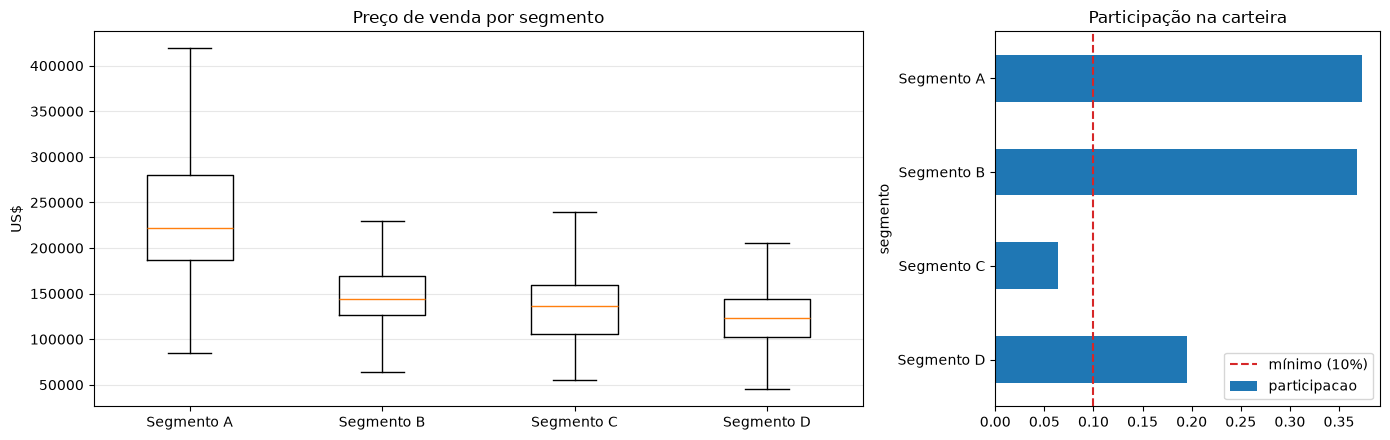

In [19]:
fig, (ax_preco, ax_fatia) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 1]})

ordem_nomes = [n for n in perfil.index if n != 'Sem segmento']
ax_preco.boxplot([df.loc[df['segmento'] == n, 'preco_venda'] for n in ordem_nomes], showfliers=False)  # preço em cada segmento
ax_preco.set_xticks(range(1, len(ordem_nomes) + 1), ordem_nomes)                    # nomes dos segmentos no eixo
ax_preco.set(title='Preço de venda por segmento', ylabel='US$')
ax_preco.grid(alpha=0.3, axis='y')

perfil['participacao'].plot.barh(ax=ax_fatia, color='tab:blue')                     # tamanho de cada segmento
ax_fatia.axvline(FATIA_MINIMA, color='tab:red', ls='--', label=f'mínimo ({FATIA_MINIMA:.0%})')
ax_fatia.set(title='Participação na carteira', xlabel='')
ax_fatia.invert_yaxis()
ax_fatia.legend()
fig.tight_layout()
plt.show()

## Validação contra os critérios de sucesso (meta 1.1)

* **Preço:** o teste de Kruskal-Wallis verifica se os segmentos têm distribuições de preço diferentes, e a razão entre medianas mede se a diferença é grande o bastante para importar.
* **Imóvel novo classificável:** uma random forest aprende a atribuir o segmento a partir das mesmas features. A acurácia em validação cruzada estima quantos imóveis novos seriam classificados corretamente. É o que viabiliza usar o modelo no dia a dia, inclusive quando o algoritmo vencedor não classifica imóveis novos sozinho (como Ward e DBSCAN).

In [20]:
rotulos = segmentos[validos]
k = len(np.unique(rotulos))                                                         # segmentos formados (sem ruído)
fatia_min = np.bincount(rotulos).min() / len(df)                                    # tamanho do menor segmento
silhueta = silhouette_score(X[validos], rotulos)                                    # recalculada na base atual

precos = [df.loc[segmentos == s, 'preco_venda'] for s in np.unique(rotulos)]
p_valor = kruskal(*precos).pvalue                                                    # p < 0,05: preços diferem entre segmentos
medianas = [p.median() for p in precos]
razao_preco = max(medianas) / min(medianas)                                          # mais caro ÷ mais barato

classificador = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
acuracia = cross_val_score(classificador, X[validos], rotulos,
                           cv=StratifiedKFold(5, shuffle=True, random_state=42)).mean()  # acerto em imóveis fora do treino

avaliacao = pd.DataFrame([  # (critério, meta, obtido, atende, crítico)
    ('Segmentos operáveis', f'{K_MIN} a {K_MAX}', f'{k}', K_MIN <= k <= K_MAX, True),
    ('Menor segmento', f'≥ {FATIA_MINIMA:.0%} da carteira', f'{fatia_min:.1%}', fatia_min >= FATIA_MINIMA, True),
    ('Preço distingue os segmentos', f'razão ≥ {RAZAO_PRECO_MINIMA} e p < 0,05', f'{razao_preco:.2f} (p = {p_valor:.1e})',
     razao_preco >= RAZAO_PRECO_MINIMA and p_valor < 0.05, True),
    ('Imóvel novo classificável', f'acurácia ≥ {ACURACIA_MINIMA:.0%}', f'{acuracia:.1%}', acuracia >= ACURACIA_MINIMA, True),
    ('Separação dos grupos', f'silhueta ≥ {SILHUETA_MINIMA}', f'{silhueta:.3f}', silhueta >= SILHUETA_MINIMA, False),
    ('Cobertura da carteira', '100% com segmento', f'{validos.mean():.1%}', validos.all(), False),
], columns=['critério', 'meta', 'obtido', 'atende', 'crítico'])

(avaliacao.assign(atende=avaliacao['atende'].map({True: '✓', False: '✗'}),
                  crítico=avaliacao['crítico'].map({True: 'sim', False: 'não'}))
 .style.hide(axis='index')
 .apply(lambda linha: ['background-color: #fde2e1' if linha['atende'] == '✗' else ''] * len(linha), axis=1))  # falhas em vermelho

critério,meta,obtido,atende,crítico
Segmentos operáveis,2 a 5,4,✓,sim
Menor segmento,≥ 10% da carteira,6.4%,✗,sim
Preço distingue os segmentos,"razão ≥ 1.3 e p < 0,05",1.80 (p = 0.0e+00),✓,sim
Imóvel novo classificável,acurácia ≥ 85%,96.0%,✓,sim
Separação dos grupos,silhueta ≥ 0.25,0.105,✗,não
Cobertura da carteira,100% com segmento,100.0%,✓,não


## Impacto financeiro e operacional

**Financeiro.** A base de cálculo é o valor de venda anual da carteira segmentada (VGV ÷ anos cobertos pela base). Sobre ela incide a comissão, e cada cenário aplica um ganho de receita atribuído à segmentação: precificação mais certeira, campanhas por perfil e menos tempo de anúncio. O resultado do ano 1 desconta a implantação e a manutenção.

In [21]:
anos = df['ano_venda'].nunique() if 'ano_venda' in df else 5        # a base de Ames cobre vendas de 2006 a 2010
vgv_anual = df.loc[validos, 'preco_venda'].sum() / anos              # valor de venda por ano, só imóveis com segmento
receita_anual = vgv_anual * COMISSAO                                 # receita de comissão hoje

cenarios = (
    pd.DataFrame({'ganho': GANHO_RECEITA})
    .assign(
        receita_extra=lambda d: receita_anual * d['ganho'],                                      # ganho por ano
        resultado_ano1=lambda d: d['receita_extra'] - CUSTO_IMPLANTACAO - CUSTO_ANUAL,          # já descontados os custos
        roi_ano1=lambda d: d['resultado_ano1'] / (CUSTO_IMPLANTACAO + CUSTO_ANUAL),            # retorno sobre o investido
        payback_meses=lambda d: (CUSTO_IMPLANTACAO / ((d['receita_extra'] - CUSTO_ANUAL) / 12))
                                .where(d['receita_extra'] > CUSTO_ANUAL),                        # sem payback se não cobre a manutenção
    )
)
display(Markdown(f'VGV anual da carteira: **${vgv_anual:,.0f}** · receita de comissão: **${receita_anual:,.0f}**/ano'))
cenarios.style.format({'ganho': '{:.0%}', 'receita_extra': '${:,.0f}', 'resultado_ano1': '${:,.0f}',
                       'roi_ano1': '{:.0%}', 'payback_meses': '{:.1f}'}, na_rep='sem payback')

VGV anual da carteira: **$105,840,771** · receita de comissão: **$6,350,446**/ano

,ganho,receita_extra,resultado_ano1,roi_ano1,payback_meses
pessimista,1%,"$63,504","$-126,496",-67%,76.6
base,3%,"$190,513",$513,0%,12.0
otimista,5%,"$317,522","$127,522",67%,6.5


In [22]:
# Operacional: o que muda na rotina da equipe
operacional = pd.DataFrame({
    'indicador': ['Playbooks comerciais a manter', 'Imóveis da carteira com segmento', 'Imóveis novos classificados corretamente',
                  'Maior segmento (concentração da carga)', 'Re-treino recomendado'],
    'valor': [f'{k} (um por segmento)', f'{validos.mean():.1%}', f'{acuracia:.1%}',
              f'{perfil["participacao"].max():.1%} da carteira', 'semestral ou a cada 10% de imóveis novos'],
})
operacional.style.hide(axis='index')

indicador,valor
Playbooks comerciais a manter,4 (um por segmento)
Imóveis da carteira com segmento,100.0%
Imóveis novos classificados corretamente,96.0%
Maior segmento (concentração da carga),37.3% da carteira
Re-treino recomendado,semestral ou a cada 10% de imóveis novos


## Decisão formal sobre a implantação

In [23]:
falhas_criticas = avaliacao.query('crítico and not atende')['critério'].tolist()
ressalvas = avaliacao.query('not crítico and not atende')['critério'].tolist()
cenario_base_positivo = cenarios.loc['base', 'resultado_ano1'] > 0

aprovado = not falhas_criticas and cenario_base_positivo             # aprova se nenhum critério crítico falha e o cenário base se paga
display(Markdown(
    f"### {'✓ Aprovado' if aprovado else '✗ Não aprovado'} para implantação\n"
    f"- critérios críticos que falharam: **{', '.join(falhas_criticas) or 'nenhum'}**\n"
    f"- ressalvas (não críticos): **{', '.join(ressalvas) or 'nenhuma'}**\n"
    f"- resultado do ano 1 no cenário base: **${cenarios.loc['base', 'resultado_ano1']:,.0f}**"
))

### ✗ Não aprovado para implantação
- critérios críticos que falharam: **Menor segmento**
- ressalvas (não críticos): **Separação dos grupos**
- resultado do ano 1 no cenário base: **$513**

| Registro da decisão | |
|---|---|
| Responsável pela aprovação | *preencher* |
| Data | *preencher* |
| Decisão | *copiar da célula acima* |
| Condições ou ressalvas aceitas | *preencher* |

# 5.2 · Revisar o processo

## Análise das fases

| Fase | Notebook | O que entregou | Status |
|---|---|---|---|
| 1 · Entendimento do negócio | 01 | meta 1.1 e critérios de sucesso | ✓ (critérios reproduzidos acima: conferir) |
| 2 · Entendimento dos dados | 01 / 02 | dicionário, escalas ordinais, diagnóstico de ausentes | ✓ |
| 3 · Preparação | 02 · 03 | base curada (2.350 × 83) · MinMax + one-hot (~210 features) | ⚠ ver lacunas 1 e 2 |
| 4 · Modelagem | 04-0 · 04-1 · 04-2 · 04-3 | 11 algoritmos comparados · cotovelos · PCA/UMAP · regras de associação | ⚠ ver lacunas 3 a 6 |
| 5 · Avaliação | 05 | este notebook | — |

## Lacunas e erros identificados

| # | Lacuna | Onde | Efeito | Correção |
|---|---|---|---|---|
| 1 | `preco_venda` e `subclasse` entravam na distância (o dicionário declara as duas como "Discreta") | 03 / 07 | agrupar pelo preço e depois descrever pelo preço é circular; `subclasse` é código, não medida | removidas no 04; **mover a remoção para o 03** |
| 2 | o one-hot com MinMax dá variância alta a categorias equilibradas | 03 | categorias dominam a distância e o PCA (visto no 04-2) | testar FAMD ou ponderar os blocos de variáveis |
| 3 | a escolha do modelo foi feita na base inteira, sem validação cruzada (Ward e DBSCAN não classificam imóveis novos) | 04-0 | risco de escolher pelo acaso | mitigado aqui pela acurácia em validação cruzada; avaliar a estabilidade por bootstrap |
| 4 | silhueta baixa em todos os algoritmos | 04-0 · 04-1 | estrutura geométrica fraca em ~200 dimensões | redução de dimensionalidade (04-2) antes do agrupamento |
| 5 | constantes do projeto (silhueta mínima, teto de ruído) definidas à mão nos notebooks | 04-1 · 05 | risco de divergir do `src.config` | centralizar no config |
| 6 | K-Medianas e K-Medoids são classes definidas no notebook | 04-0 | o `.joblib` só carrega onde a classe existe | o 04-0 agora salva `segmentos.csv`; mover as classes para `src` |
| 7 | premissas financeiras sem validação | 05 | o impacto pode estar super ou subestimado | validar comissão, ganho e custos com a área comercial |

## Sumário das descobertas

O que diferencia os segmentos: a importância de cada variável no classificador, somada por variável de origem (o one-hot é desfeito).

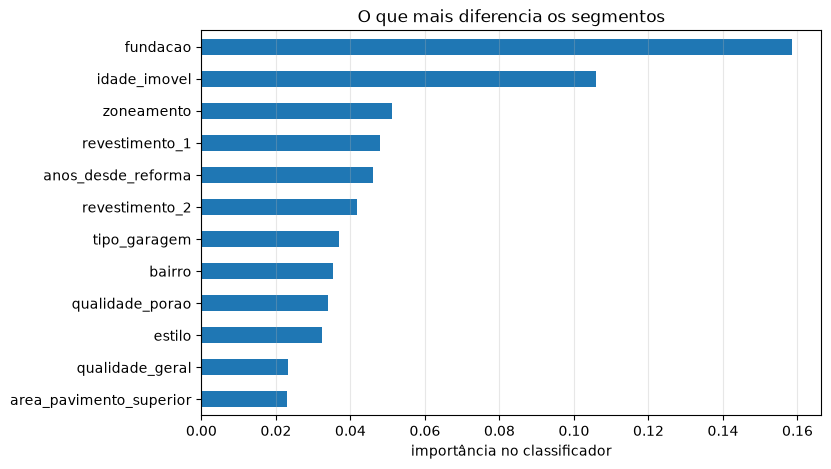

In [24]:
classificador.fit(X[validos], rotulos)                                              # treina na carteira inteira para ler as importâncias
variavel = {c: max((o for o in df.columns if c == o or c.startswith(f'{o}_')), key=len, default=c)
            for c in base.columns}                                                  # feature → variável de origem
importancia = (pd.Series(classificador.feature_importances_, index=base.columns)
               .groupby(variavel).sum().sort_values(ascending=False))                # relevância por variável

ax = importancia.head(12)[::-1].plot.barh(figsize=(8, 5), color='tab:blue')
ax.set(title='O que mais diferencia os segmentos', xlabel='importância no classificador')
ax.grid(alpha=0.3, axis='x')
plt.show()

In [25]:
descobertas = [
    f"A carteira foi dividida em **{k} segmentos** pelo {selecionado['modelo']}; o menor tem {fatia_min:.1%} dos imóveis.",
    f"O preço mediano vai de **${min(medianas):,.0f}** a **${max(medianas):,.0f}** ({razao_preco:.2f}×) entre os segmentos.",
    f"As variáveis que mais separam os segmentos são **{', '.join(importancia.index[:3])}**.",
    f"Um imóvel novo é atribuído ao segmento certo em **{acuracia:.1%}** dos casos.",
    f"A separação geométrica é {'adequada' if silhueta >= SILHUETA_MINIMA else '**fraca**'} (silhueta {silhueta:.3f}): "
    "os segmentos são faixas de uma carteira contínua, não grupos isolados.",
]
limitacoes = [
    "A base é histórica (vendas de 2006 a 2010 em Ames, EUA): a representatividade para a carteira atual da Meridiano precisa ser confirmada.",
    "O modelo descreve imóveis, não compradores: o perfil de quem compra cada segmento ainda não foi medido.",
    "O impacto financeiro depende de premissas não validadas (seção 5.1).",
    "Os segmentos refletem as escolhas de pré-processamento do 03; com outro peso para o one-hot, eles podem mudar.",
]
display(Markdown('**Descobertas**\n' + '\n'.join(f'- {d}' for d in descobertas)
                 + '\n\n**Limitações do modelo**\n' + '\n'.join(f'- {l}' for l in limitacoes)))

**Descobertas**
- A carteira foi dividida em **4 segmentos** pelo mini batch k-means; o menor tem 6.4% dos imóveis.
- O preço mediano vai de **$123,500** a **$222,500** (1.80×) entre os segmentos.
- As variáveis que mais separam os segmentos são **fundacao, idade_imovel, zoneamento**.
- Um imóvel novo é atribuído ao segmento certo em **96.0%** dos casos.
- A separação geométrica é **fraca** (silhueta 0.105): os segmentos são faixas de uma carteira contínua, não grupos isolados.

**Limitações do modelo**
- A base é histórica (vendas de 2006 a 2010 em Ames, EUA): a representatividade para a carteira atual da Meridiano precisa ser confirmada.
- O modelo descreve imóveis, não compradores: o perfil de quem compra cada segmento ainda não foi medido.
- O impacto financeiro depende de premissas não validadas (seção 5.1).
- Os segmentos refletem as escolhas de pré-processamento do 03; com outro peso para o one-hot, eles podem mudar.

# 5.3 · Determinar as próximas etapas

A próxima ação sai de uma regra declarada antes de olhar o resultado:

| Situação | Próxima ação |
|---|---|
| nenhum critério crítico falha e o cenário base se paga | **Implantação**, com as ressalvas registradas |
| algum critério crítico falha ou o cenário base não se paga, mas a maioria dos critérios é atendida | **Iterar mais**: voltar às fases 3 e 4 com as correções das lacunas |
| a maioria dos critérios falha | **Novo projeto**: revisar a pergunta de negócio ou os dados |

In [26]:
acoes = {  # critério que falhou → o que fazer na próxima iteração
    'Segmentos operáveis': 'restringir k à faixa do negócio na regra de escolha do 04-0',
    'Menor segmento': 'subir o tamanho mínimo de segmento na regra do 04-0 ou fundir segmentos pequenos',
    'Preço distingue os segmentos': 'agrupar sobre as bases reduzidas do 04-2 ou com FAMD',
    'Imóvel novo classificável': 'treinar e validar um classificador supervisionado sobre os segmentos',
    'Separação dos grupos': 'reduzir a dimensionalidade (04-2) e revisar o peso do one-hot no 03',
    'Cobertura da carteira': 'atribuir o ruído ao segmento mais próximo ou trocar o algoritmo de densidade',
    'Retorno financeiro': 'revalidar ganho e custos com a Meridiano: no cenário base o investimento não se paga no ano 1',
}

if aprovado:
    proxima = 'Implantação'
elif avaliacao['atende'].mean() >= 0.5:
    proxima = 'Iterar mais'
else:
    proxima = 'Novo projeto'

falhas = avaliacao.query('not atende')['critério'].tolist() + ([] if cenario_base_positivo else ['Retorno financeiro'])
justificativa = (
    f"{avaliacao['atende'].sum()} de {len(avaliacao)} critérios atendidos; "
    f"críticos com falha: {', '.join(falhas_criticas) or 'nenhum'}; "
    f"resultado do ano 1 no cenário base: ${cenarios.loc['base', 'resultado_ano1']:,.0f}."
)
display(Markdown(
    f'### Próxima ação: {proxima}\n**Justificativa:** {justificativa}\n\n'
    + ('**Ações para cada critério não atendido:**\n' + '\n'.join(f'- *{f}*: {acoes[f]}' for f in falhas) if falhas else '')
    + ('\n\n**Para a implantação:** expor o classificador para atribuir imóveis novos, publicar os playbooks por segmento e '
       'agendar o re-treino.' if proxima == 'Implantação' else '')
))

### Próxima ação: Iterar mais
**Justificativa:** 4 de 6 critérios atendidos; críticos com falha: Menor segmento; resultado do ano 1 no cenário base: $513.

**Ações para cada critério não atendido:**
- *Menor segmento*: subir o tamanho mínimo de segmento na regra do 04-0 ou fundir segmentos pequenos
- *Separação dos grupos*: reduzir a dimensionalidade (04-2) e revisar o peso do one-hot no 03

In [27]:
Path('../reports').mkdir(exist_ok=True)  # garante a pasta de relatórios
Path('../reports/05-avaliacao.json').write_text(json.dumps({   # registro da avaliação, para auditoria e para a fase 6
    'modelo': selecionado,
    'criterios': avaliacao.to_dict(orient='records'),
    'cenarios_financeiros': cenarios.round(2).reset_index(names='cenario').to_dict(orient='records'),
    'aprovado': bool(aprovado),
    'proxima_acao': proxima,
    'justificativa': justificativa,
}, ensure_ascii=False, indent=2, default=lambda v: v.item() if hasattr(v, 'item') else str(v)), encoding='utf-8')
print('Avaliação registrada em ../reports/05-avaliacao.json')

Avaliação registrada em ../reports/05-avaliacao.json


| Registro da próxima etapa | |
|---|---|
| Decisão | *copiar da célula acima* |
| Justificativa complementar (contexto de negócio) | *preencher* |
| Responsável | *preencher* |
| Prazo da próxima entrega | *preencher* |